In [4]:
# ---
# title: "Time Series Linear Model (Python Edition)"
# author: "Vince Garcia"
# LLMS: Gemini 4 Hyrdogen to turn the R notebook into a Python notebook
# ---
# ## IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.deterministic import DeterministicProcess
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error



In [6]:
# Set default plot size for better visibility
plt.rcParams['figure.figsize'] = (12, 6)

# ## Load the data
data = pd.read_csv(r"C:\Users\Vince\OneDrive\Documents\USD\Applied Time Series\Final Project\residential_electricity.csv")

In [7]:
# ## Convert to Time Series (Pandas DatetimeIndex)
# Convert date to datetime and set as index
data['date'] = pd.to_datetime(data['date'])
electric = data[['date', 'residential_million_kwh']].copy()
electric = electric.rename(columns={'residential_million_kwh': 'Value'})
electric.set_index('date', inplace=True)
electric = electric.asfreq('MS') # Set monthly start frequency

In [8]:
 ## Train test split
TR = electric.loc['2010-01-01':'2025-01-31'].copy()
test = electric.loc['2025-01-01':'2026-07-31'].copy()

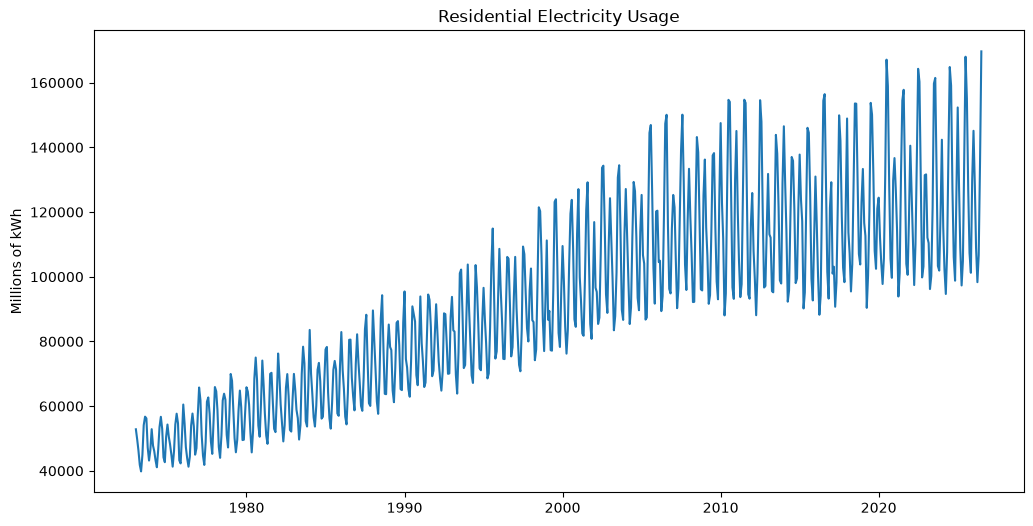

In [9]:
# # First glance
plt.plot(electric.index, electric['Value'])
plt.title('Residential Electricity Usage')
plt.ylabel('Millions of kWh')
plt.show()

In [10]:
# # Transformed Data
electric['log_v'] = np.log(electric['Value'])
electric['d1'] = electric['log_v'].diff()

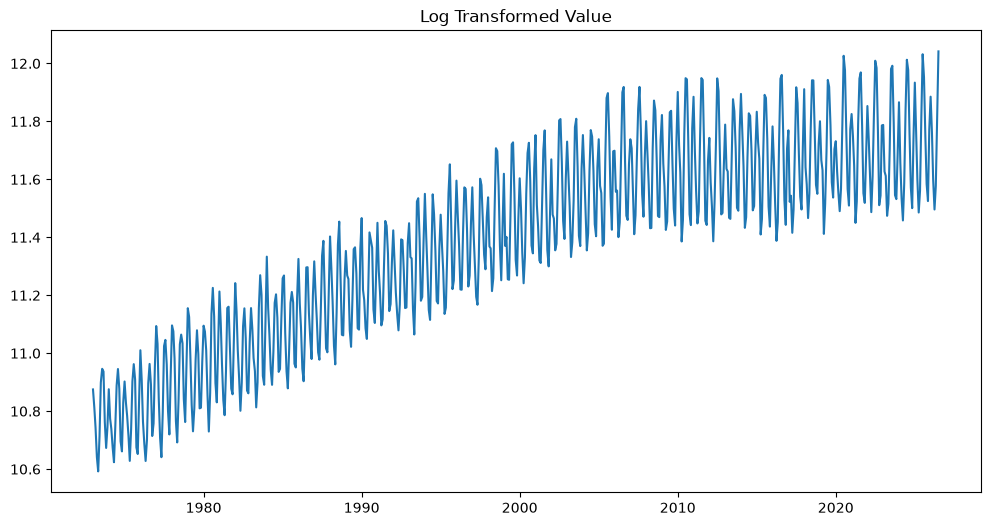

In [11]:
# # Log Transformed Data
plt.plot(electric.index, electric['log_v'])
plt.title('Log Transformed Value')
plt.show()

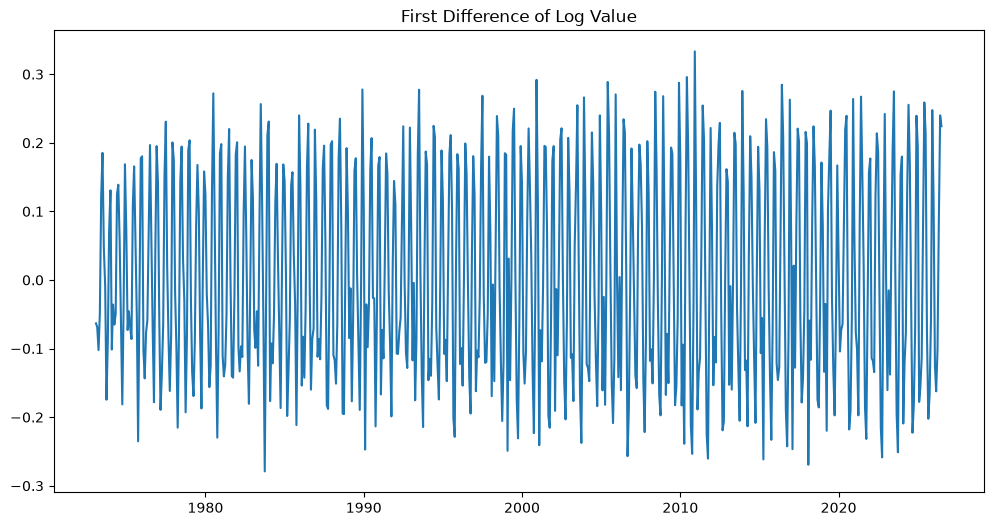

In [12]:
# # Evaluating log-transformed, differenced data
plt.plot(electric.index, electric['d1'])
plt.title('First Difference of Log Value')
plt.show()

In [13]:
# # Transform training data
TR['log_v'] = np.log(TR['Value'])
TR['d1'] = TR['log_v'].diff()
# Drop the first NaN row created by differencing for modeling
train_diff = TR.dropna(subset=['d1']).copy()

In [14]:
# # TSLM - auto (Python Equivalent using statsmodels and DeterministicProcess)
# Create deterministic trend and seasonal features (12 periods for monthly)
dp = DeterministicProcess(
    index=TR.index, 
    constant=True, 
    order=1, # Linear Trend
    seasonal=True, 
    period=12 # Monthly seasonality
)
X = dp.in_sample()

# Align X with the differenced training data (missing the first row)
X_diff = X.loc[train_diff.index]
y_diff = train_diff['d1']

TSLM_fit = sm.OLS(y_diff, X_diff).fit()
print(TSLM_fit.summary())

# # TSLM - unmodified
y_unmodified = TR['Value']

TSLM_fit_unmodified = sm.OLS(y_unmodified, X).fit()
print(TSLM_fit_unmodified.summary())


                            OLS Regression Results                            
Dep. Variable:                     d1   R-squared:                       0.931
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     186.7
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           4.96e-90
Time:                        03:21:43   Log-Likelihood:                 311.57
No. Observations:                 180   AIC:                            -597.1
Df Residuals:                     167   BIC:                            -555.6
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1116      0.013      8.548      0.0

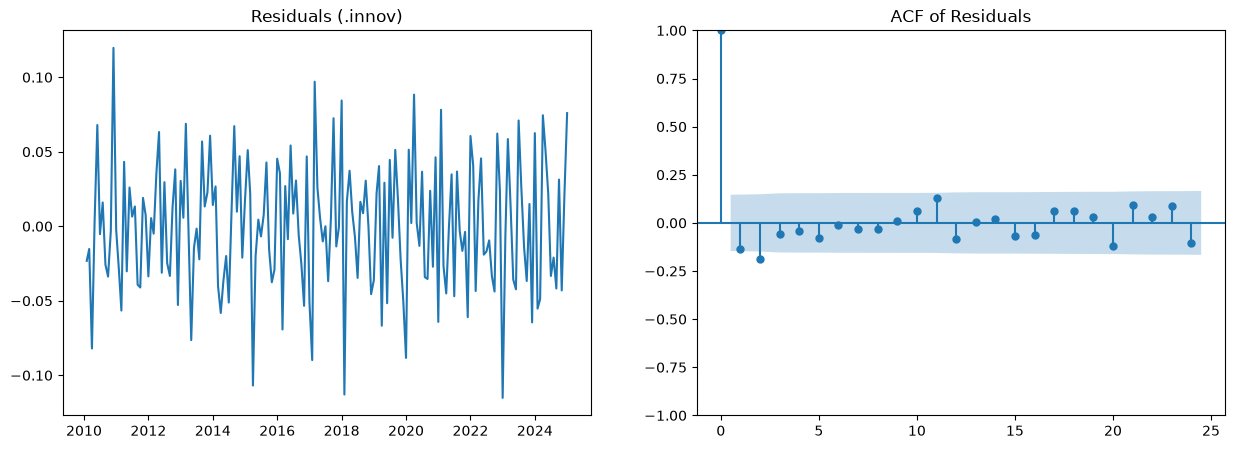

In [15]:
# # Noise / Residual Plot (Differenced Model)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(TSLM_fit.resid)
ax[0].set_title('Residuals (.innov)')

sm.graphics.tsa.plot_acf(TSLM_fit.resid, lags=24, ax=ax[1])
ax[1].set_title('ACF of Residuals')
plt.show()


In [16]:
# # Ljung-Box test
# Testing Unmodified Model Residuals
ljung_box_unmod = acorr_ljungbox(TSLM_fit_unmodified.resid, lags=[12], return_df=True)
print("Ljung-Box Test (Unmodified Model):")
print(ljung_box_unmod)

Ljung-Box Test (Unmodified Model):
      lb_stat     lb_pvalue
12  80.063774  4.013309e-12


In [17]:

# Degrees of freedom calculation context
coef_unmod = len(TSLM_fit_unmodified.params)
res_df_unmod = len(TR) - coef_unmod
print(f"\nTSLM Unmodified: Coefs={coef_unmod}, Residual DF={res_df_unmod}")


TSLM Unmodified: Coefs=13, Residual DF=168


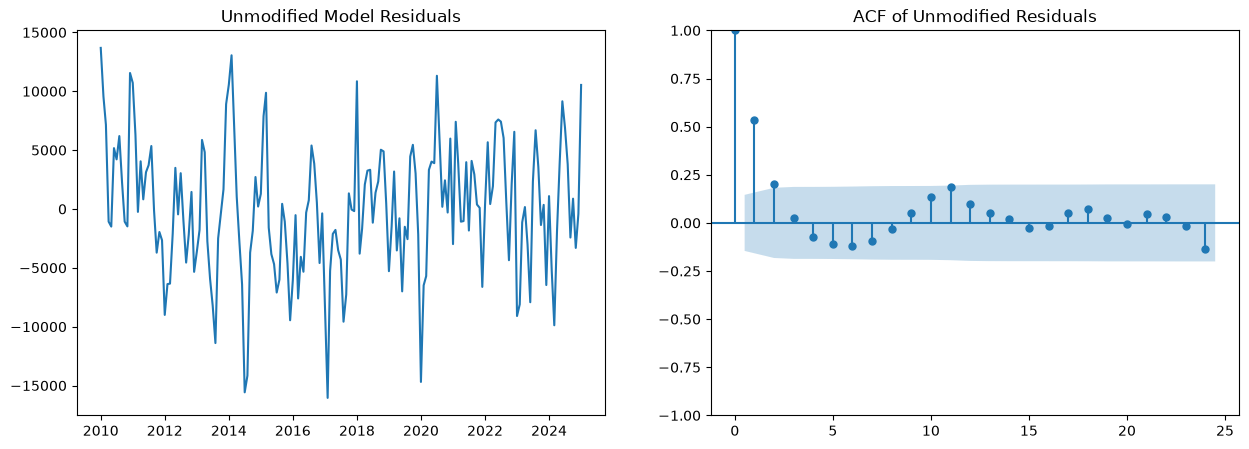

In [18]:
# # Noise test (Unmodified)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(TSLM_fit_unmodified.resid)
ax[0].set_title('Unmodified Model Residuals')

sm.graphics.tsa.plot_acf(TSLM_fit_unmodified.resid, lags=24, ax=ax[1])
ax[1].set_title('ACF of Unmodified Residuals')
plt.show()

In [19]:

# # Ljung-Box test (Differenced Model)
ljung_box_diff = acorr_ljungbox(TSLM_fit.resid, lags=[12], return_df=True)
print("Ljung-Box Test (Differenced Model):")
print(ljung_box_diff)

Ljung-Box Test (Differenced Model):
      lb_stat  lb_pvalue
12  17.785299   0.122367


In [20]:
# # Forecasting both TSLM models on the holdout set

# Generate out-of-sample deterministic features for the test period
X_test = dp.out_of_sample(steps=len(test))

# 1. Unmodified Forecast
fc_unmod = TSLM_fit_unmodified.predict(X_test)

# 2. Differenced Model Forecast (Requires undifferencing and un-logging)
pred_diff = TSLM_fit.predict(X_test)
# Reconstruct the log values based on the last known log_v
last_log_v = TR['log_v'].iloc[-1]
fc_log = [last_log_v]
for diff_val in pred_diff:
    fc_log.append(fc_log[-1] + diff_val)
fc_log = fc_log[1:] # Drop the initial value
# Un-log to get actual predictions
fc_diff_actuals = np.exp(fc_log)

In [21]:
# Calculate Accuracy Metrics
def get_metrics(actual, pred, name):
    return pd.DataFrame({
        'Model': [name],
        'RMSE': [np.sqrt(mean_squared_error(actual, pred))],
        'MAE': [mean_absolute_error(actual, pred)],
        'MAPE': [mean_absolute_percentage_error(actual, pred) * 100]
    })

metrics_unmod = get_metrics(test['Value'], fc_unmod, "TSLM Unmodified")
metrics_diff = get_metrics(test['Value'], fc_diff_actuals, "TSLM Differenced")

accuracy_df = pd.concat([metrics_unmod, metrics_diff], ignore_index=True)
display(accuracy_df)

,Model,RMSE,MAE,MAPE
0,TSLM Unmodified,18930.708303,17392.590561,13.813946
1,TSLM Differenced,24157.757203,18761.278053,15.675506


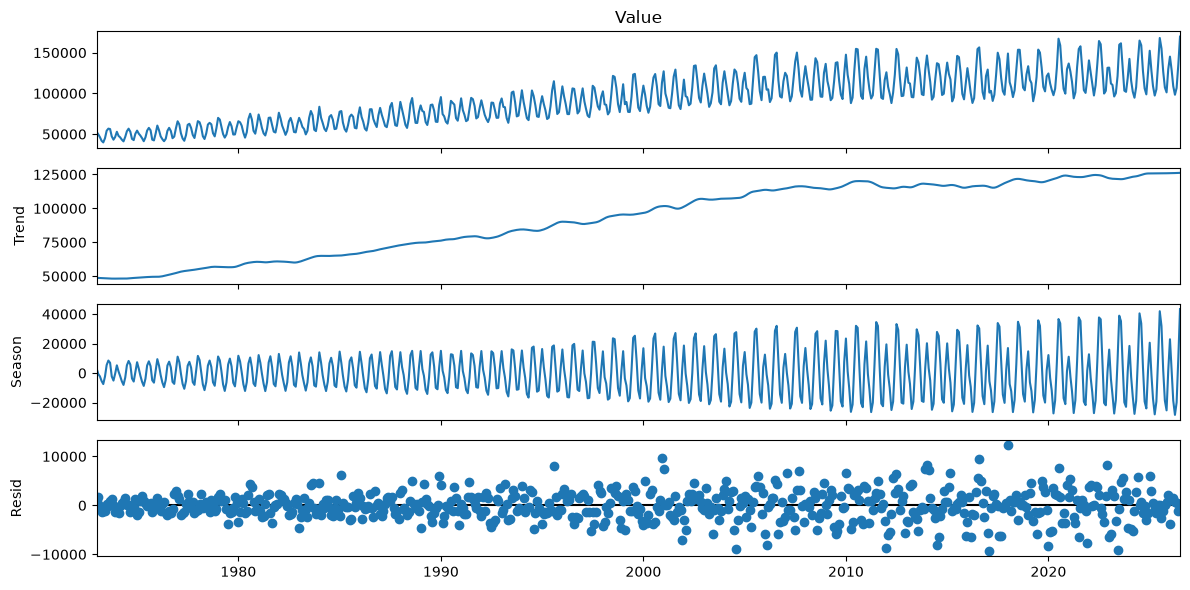

In [22]:
# # Decomposition (STL)
stl = STL(electric['Value'], period=12)
res = stl.fit()
fig = res.plot()
plt.show()

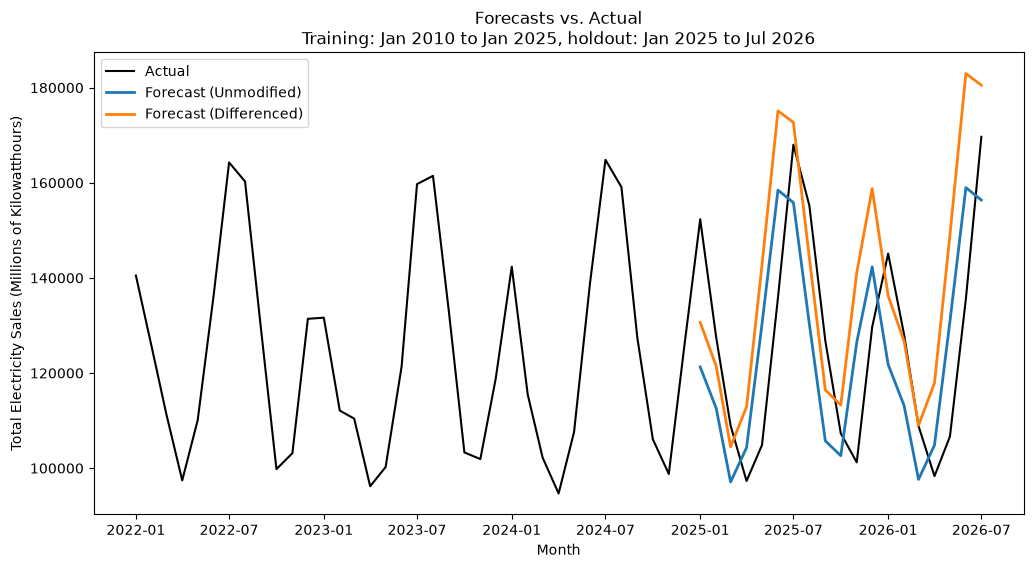

In [23]:
# # Plot Forecasts vs Actuals
actual_plot_data = electric.loc['2022-01-01':]

plt.plot(actual_plot_data.index, actual_plot_data['Value'], color='black', label='Actual')
plt.plot(test.index, fc_unmod, linewidth=2, label='Forecast (Unmodified)')
plt.plot(test.index, fc_diff_actuals, linewidth=2, label='Forecast (Differenced)')

plt.title('Forecasts vs. Actual\nTraining: Jan 2010 to Jan 2025, holdout: Jan 2025 to Jul 2026')
plt.ylabel('Total Electricity Sales (Millions of Kilowatthours)')
plt.xlabel('Month')
plt.legend()
plt.show()